# Simulação de aplicação — envio de dados pela área cliente

Leitura da rodada já executada, sem treinamento ou geração de novos dados. O upload é um CSV local fictício, acompanhado de histórico anterior. O gabarito permanece separado da inferência. Esta rodada complementa o experimento original e os desafios de robustez.


In [1]:
from pathlib import Path
import sys

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "ml").is_dir() and (p / "sql").is_dir()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS

get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)

import json
from ml.client_demo import DATASET, DESTINATION
from ml.client_demo_report import make_figures, load_results
from ml.data import sha256

manifest, metrics, evaluated, segments = load_results()
manifest_path = DATASET / "manifesto.json"
for name, expected in manifest["arquivos_sha256"].items():
    assert sha256(DATASET / name) == expected, f"Entrada alterada: {name}"
integrity = json.loads((DESTINATION / "integridade.json").read_text(encoding="utf-8"))
assert sha256(manifest_path) == integrity["dataset_sha256"]
for name, expected in integrity["resultados_sha256"].items():
    assert sha256(DESTINATION / name) == expected, f"Resultado alterado: {name}"


## 1. Arquivo enviado e saída operacional

Os dados abaixo não possuem rótulos. `CONTEXTO_INSUFICIENTE` significa menos de cinco observações anteriores; ausência de alerta não atesta normalidade.

In [2]:
display(style_table(pd.read_csv(DATASET / "lote_cliente.csv").head(8)))
display(style_table(pd.read_csv(DESTINATION / "predicoes_upload.csv").head(8).round(3)))

id_transacao_natural,data,id_parceiro_natural,valor_bruto,tipo_transacao,id_area_natural,id_categoria_natural
DUMMY-T000048,2026-04-01,DUMMY-P002,3211.800000,RECEITA,VND,37
DUMMY-T000176,2026-04-01,DUMMY-P004,3043.700000,DESPESA,TI,21
DUMMY-T000249,2026-04-01,DUMMY-P005,1473.770000,RECEITA,ESG,32
DUMMY-T000309,2026-04-01,DUMMY-P006,15594.900000,RECEITA,MKT,35
DUMMY-T000396,2026-04-01,DUMMY-P008,6780.330000,DESPESA,COM,24
DUMMY-T000446,2026-04-01,DUMMY-P009,3322.070000,RECEITA,COM,37
DUMMY-T000484,2026-04-01,DUMMY-P010,701.980000,RECEITA,VND,33
DUMMY-T000674,2026-04-01,DUMMY-P014,3614.860000,DESPESA,QAS,29


id_transacao_natural,data,id_parceiro_natural,valor_bruto,tipo_transacao,id_area_natural,id_categoria_natural,qtd_historico,sem_historico,score,limiar,alerta,contexto_suficiente,parceiro_novo_no_lote,situacao
DUMMY-T000048,2026-04-01,DUMMY-P002,3211.800000,RECEITA,VND,37,19,0,0.107000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000176,2026-04-01,DUMMY-P004,3043.700000,DESPESA,TI,21,53,0,0.147000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000249,2026-04-01,DUMMY-P005,1473.770000,RECEITA,ESG,32,54,0,0.002000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000309,2026-04-01,DUMMY-P006,15594.900000,RECEITA,MKT,35,43,0,0.014000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000396,2026-04-01,DUMMY-P008,6780.330000,DESPESA,COM,24,28,0,0.520000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000446,2026-04-01,DUMMY-P009,3322.070000,RECEITA,COM,37,39,0,2.187000,1.681000,True,True,False,REVISAR
DUMMY-T000484,2026-04-01,DUMMY-P010,701.980000,RECEITA,VND,33,24,0,0.958000,1.681000,False,True,False,SEM_ALERTA
DUMMY-T000674,2026-04-01,DUMMY-P014,3614.860000,DESPESA,QAS,29,52,0,0.711000,1.681000,False,True,False,SEM_ALERTA


## 2. Resultados e cobertura por segmento

Recall é mostrado quando há adulterações no segmento; FPR quando há normais. Células vazias não são zero. Segmentos podem se sobrepor.

In [3]:
display(style_table(pd.DataFrame([metrics]).round(4)))
display(style_table(segments.round(4)))

average_precision,roc_auc,precision,recall,f1,precision_top_5pct,recall_top_5pct,alertas,taxa_alerta,tn,fp,fn,tp,limiar,n,anomalias,prevalencia
0.239500,0.690700,0.148500,0.447800,0.223000,0.278500,0.328400,202,0.129300,1323,172,37,30,1.681200,1562,67,0.042900


segmento,n,anomalias,alertas,tp,fp,recall,fpr
Lote completo,1562,67,202,30,172,0.447800,0.115100
Parceiros recorrentes,1277,57,181,27,154,0.473700,0.126200
Parceiros novos,285,10,21,3,18,0.300000,0.065500
Contexto insuficiente (<5),100,4,0,0,0,0.000000,0.000000
Contexto suficiente (>=5),1462,63,202,30,172,0.476200,0.122900
Adulterações amplas,27,27,24,24,0,0.888900,nan
Adulterações sutis,40,40,6,6,0,0.150000,nan
Normais com pico legítimo,27,0,19,0,19,nan,0.703700
Normais em regime novo,163,0,74,0,74,nan,0.454000


## 3. Visualizações

Fonte: elaboração própria, dados sintéticos SCAP. Limiar fixado na validação original; nenhuma curva recalibra o modelo.

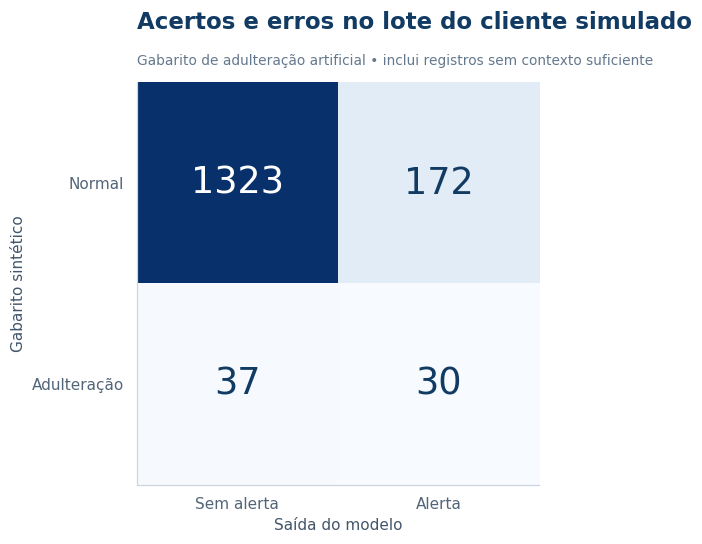

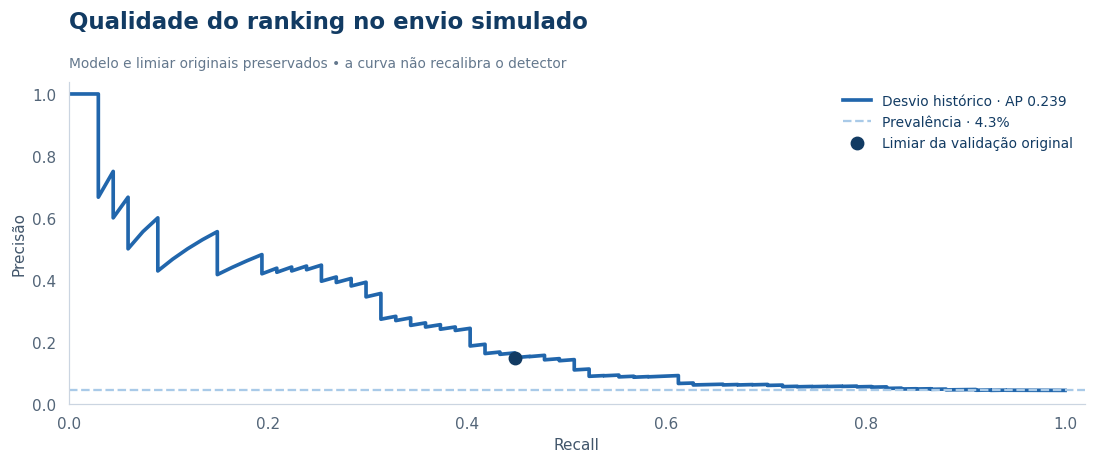

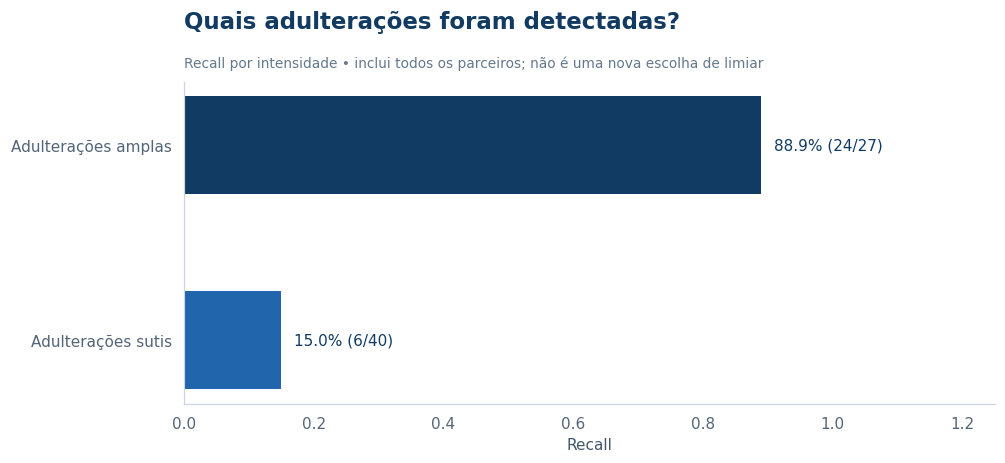

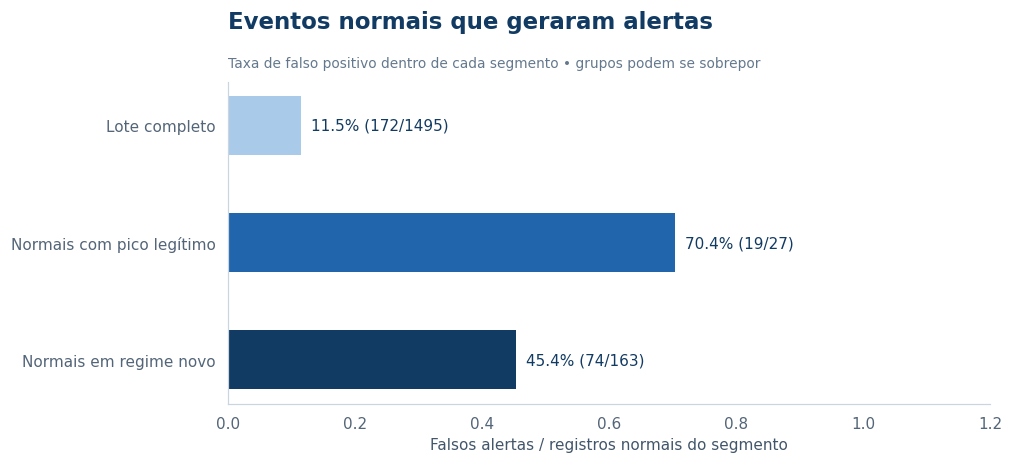

In [4]:
figures = make_figures()
for figure in figures:
    display(figure)
    plt.close(figure)

## 4. Casos para inspeção

O gabarito aparece somente nesta avaliação posterior. Os exemplos não servem para ajustar o limiar desta rodada.

In [5]:
cases = evaluated[evaluated.resultado.isin(["FP", "FN"])].sort_values(
    "score", ascending=False
)
display(
    style_table(
        cases[
            [
                "id_transacao_natural",
                "data",
                "valor_bruto",
                "qtd_historico",
                "score",
                "situacao",
                "resultado",
                "mecanismo",
                "pico_legitimo",
                "regime_novo",
            ]
        ]
        .head(12)
        .round(3)
    )
)

id_transacao_natural,data,valor_bruto,qtd_historico,score,situacao,resultado,mecanismo,pico_legitimo,regime_novo
DUMMY-T004705,2026-04-22 00:00:00,94797.910000,39,6.076000,REVISAR,FP,normal,True,False
DUMMY-T002904,2026-04-06 00:00:00,9240.440000,50,5.940000,REVISAR,FP,normal,True,False
DUMMY-T000529,2026-04-29 00:00:00,6904.990000,37,5.115000,REVISAR,FP,normal,True,False
DUMMY-T000524,2026-04-14 00:00:00,5208.570000,32,4.863000,REVISAR,FP,normal,True,False
DUMMY-T002351,2026-04-10 00:00:00,4539.250000,55,4.598000,REVISAR,FP,normal,True,False
DUMMY-T003415,2026-04-15 00:00:00,3011.130000,45,4.581000,REVISAR,FP,normal,True,False
DUMMY-T001398,2026-04-28 00:00:00,35611.220000,59,4.478000,REVISAR,FP,normal,True,False
DUMMY-T002056,2026-04-06 00:00:00,27319.200000,24,4.465000,REVISAR,FP,normal,False,True
DUMMY-T000025,2026-04-07 00:00:00,6455.270000,24,3.960000,REVISAR,FP,normal,False,True
DUMMY-T004196,2026-04-20 00:00:00,6111.640000,58,3.870000,REVISAR,FP,normal,True,False


## 5. Conclusões

In [6]:
display(Markdown((DESTINATION / "RESULTADOS_CLIENTE.md").read_text(encoding="utf-8")))

# Simulação de envio de dados pela área cliente

## Desenho e origem

Esta rodada simula uma área cliente que fornece histórico de janeiro a março de 2026 e envia um lote de abril de 2026. Os dados são inteiramente artificiais, em BRL, produzidos por um gerador novo, sem copiar transações ou valores do treino. Reutilizam-se apenas códigos válidos de tipo/área/categoria. A seed é 731927; as regras e os hashes foram registrados localmente antes de gerar dados ou medir resultados.

Há 100 parceiros recorrentes e 20 parceiros com entrada prevista em abril. As datas representam o cenário simulado, não a data real de coleta de um cliente. O histórico tem **3,721 transações**, e o lote tem **1,562 transações**, de **01/04/2026 a 30/04/2026**. Foram observados 120 parceiros no lote.

O gerador usa escalas próprias por parceiro, dispersão log entre 0,12 e 0,28, frequência variável, pequena tendência e padrão semanal. A probabilidade de adulteração é 4% por registro, tanto no histórico quanto no lote; metade das adulterações, em expectativa, é sutil. A realização efetiva não precisa coincidir exatamente com essas proporções. Adulterações sutis usam fatores 1,1–1,3 ou 0,7–0,9; amplas usam 1,5–2,5 ou 0,35–0,65. Picos legítimos podem ocorrer em registros normais (probabilidade condicional de 1,5%). Quinze parceiros recorrentes passam a operar em nível 1,6 vez maior em abril, como mudança legítima.

## Separação entre entrada, inferência e avaliação

- `historico_cliente.csv`: contexto anterior ao lote, com sete campos observáveis.
- `lote_cliente.csv`: arquivo que representa o upload, com os mesmos sete campos e sem gabarito.
- `gabarito_avaliacao.csv`: adulterações, fatores e eventos legítimos; exclusivo da avaliação posterior, separado da inferência.
- `predicoes_upload.csv`: saída por transação, sem rótulos; score, limiar, alerta e indicação de contexto insuficiente.

O modelo **Desvio historico**, escolhido anteriormente na validação original, foi aplicado com limiar **1.681246**, sem treinamento, recalibração ou seleção de outro modelo. O histórico usa apenas dias anteriores; registros anteriores do próprio lote atualizam o contexto. Todos os registros do mesmo dia compartilham o mesmo passado. O CSV completo de abril não é usado como referência global para pontuar o início do mês.

O envio é simulado pelo processamento local de CSV. Não foi implementada uma interface web nem realizado um envio real por cliente. O modo `--score-only` permite repetir apenas a inferência sem abrir o gabarito. Com menos de cinco observações passadas, o baseline zera o score; a saída marca **CONTEXTO_INSUFICIENTE**, que não deve ser interpretado como comprovação de normalidade. Esses registros permanecem nas métricas globais.

## Resultados do lote

| Indicador | Resultado |
|---|---:|
| Transações avaliadas | 1562 |
| Adulterações no gabarito | 67 |
| Prevalência | 4.29% |
| Alertas | 202 (12.93%) |
| Verdadeiros positivos | 30 |
| Falsos positivos | 172 |
| Falsos negativos | 37 |
| Verdadeiros negativos | 1323 |
| Precisão | 14.85% |
| Recall | 44.78% |
| F1 | 0.2230 |
| Average Precision | 0.2395 |

## Principais conclusões

1. **Intensidade da adulteração:** o detector identificou 24 de 27 adulterações amplas (recall 88.9%) e 6 de 40 sutis (recall 15.0%). Essa diferença descreve esta realização; não é uma estimativa precisa para uma população empresarial.
2. **Custo de revisão:** 172 dos 202 alertas foram falsos positivos em relação ao alvo de adulteração. A legitimidade não é inferida pelo score. O fluxo exige revisão humana, sem garantia de que cada alerta represente irregularidade.
3. **Eventos legítimos:** 19 de 27 picos legítimos receberam alerta (FPR 70.4%). Entre normais em regime novo, foram 74 de 163 (FPR 45.4%). Esses segmentos podem se sobrepor; não some seus totais. Um pico legítimo pode ser um alerta estatístico válido, embora seja falso positivo para o alvo de adulteração.
4. **Entrada de parceiros:** 285 registros pertencem a parceiros novos. Em todo o lote, 100 registros tiveram menos de cinco observações anteriores, incluindo 4 adulterações. Essa limitação deve aparecer na avaliação de cobertura, além das métricas agregadas.
5. **Transferência do limiar:** o mesmo modelo e o mesmo limiar foram usados em uma nova construção sintética. O desempenho observado mede a aplicação congelada sob esse desenho; a análise não permite atribuir todas as falhas a uma causa única nem concluir que recalibração as resolveria.

## Interpretação dos resultados

“Foi conduzida uma simulação de recebimento de dados por uma área cliente, composta por um histórico anterior e um lote mensal de 1562 transações artificiais. O detector previamente selecionado foi aplicado sem novo ajuste de pesos ou limiar. Foram emitidos 202 alertas, com 30 adulterações identificadas, 172 falsos positivos e 37 falsos negativos, resultando em precisão de 14.85%, recall de 44.78% e F1 de 0.2230. A análise por segmento evidenciou a sensibilidade à intensidade das adulterações, aos eventos legítimos atípicos e à disponibilidade de histórico. Os resultados caracterizam o comportamento do fluxo em uma simulação controlada e não constituem validação operacional com dados de clientes reais.”

## Limites e uso futuro

Esta rodada usa **uma seed, um cliente fictício e um mês**. Foi desenhada após conhecer os testes anteriores; é uma avaliação complementar de um fluxo de aplicação, não um estudo cego ou evidência independente da hipótese que motivou o desenho. Não fornece intervalo de generalização, validação externa ou prova de detecção de fraude. Dado sintético novo não equivale a dado real de cliente.

Os resultados não substituem as métricas originais nem as três seeds de robustez. Esta rodada representa uma **simulação de aplicação em lote de cliente fictício**. Após esta análise, o lote passa a ser conhecido; melhorias motivadas por ele exigem outra fonte reservada. Nenhum parâmetro foi alterado em resposta ao resultado desta rodada.

## Arquivos e reprodução

Dataset: `ml/datasets/cliente_dummy_01/`. Protocolo, saída da inferência, métricas e análise detalhada: `ml/reports/cliente_dummy/rodada_01/`. Figuras em PNG/SVG: `ml/reports/figures/cliente_dummy/rodada_01/`. Execute `python -m ml.client_demo` para reproduzir a rodada com verificações de integridade. Consulte o README principal para o contrato de entrada e a execução sem gabarito.
